In [5]:
import matplotlib.pyplot as plt

# Total for each community district over the whole period
cd_total = (
    df.groupby(["community_district", "cd_label", "borough"])
      [["new_units", "new_filings", "crashes", "severe_inj"]]
      .sum()
      .reset_index()
)
print(cd_total.sort_values("new_units", ascending=False).head(10))
print(cd_total[["new_units", "severe_inj"]].corr(method="spearman"))

    community_district cd_label    borough  new_units  new_filings  crashes  \
42                 401    QN 01     QUEENS       8845          160      216   
28                 305    BK 05   BROOKLYN       7276          177      273   
24                 301    BK 01   BROOKLYN       6863          206      307   
53                 412    QN 12     QUEENS       6431          344      311   
29                 306    BK 06   BROOKLYN       5774          113      140   
15                 204    BX 04      BRONX       5660           71      233   
18                 207    BX 07      BRONX       5307           96      174   
3                  104    MN 04  MANHATTAN       4636           36      234   
17                 206    BX 06      BRONX       4591          103      138   
12                 201    BX 01      BRONX       4373           71      272   

    severe_inj  
42         224  
28         294  
24         319  
53         334  
29         148  
15         249  
18         

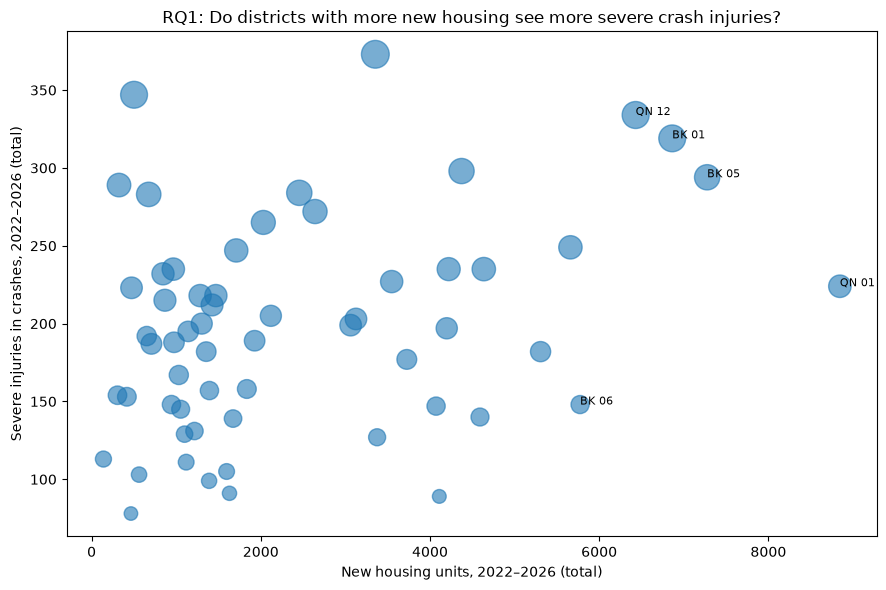

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    cd_total["new_units"],
    cd_total["severe_inj"],
    s=cd_total["crashes"] / cd_total["crashes"].max() * 400,  # bubble size = total crashes
    alpha=0.6,
)
# Label the five districts with the most new units
for _, row in cd_total.nlargest(5, "new_units").iterrows():
    ax.annotate(row["cd_label"], (row["new_units"], row["severe_inj"]), fontsize=8)

ax.set_xlabel("New housing units, 2022–2026 (total)")
ax.set_ylabel("Severe injuries in crashes, 2022–2026 (total)")
ax.set_title("RQ1: Do districts with more new housing see more severe crash injuries?")
plt.tight_layout()
plt.show()

## RQ1: Do districts with more new housing see more severe crash injuries?

Each point is a community district, and bubble size shows total crashes from 2022 to 2026. The Spearman correlation between total new housing units and total severe injuries across the 59 districts is 0.26. This is a weak positive relationship and is only borderline statistically significant.

Districts with more new housing units tend to have somewhat more severe injuries, but this does not show that new housing causes more injuries. Larger districts have more of everything, so the pattern may reflect district size and traffic volume. A fairer comparison would use rates per resident or per road mile, which requires population and road data not yet in this analysis.

   lag_months      corr
0           0  0.022827
1           1  0.027397
2           2  0.021958
3           3  0.022308
4           4  0.035835
5           5  0.024565
6           6  0.040557


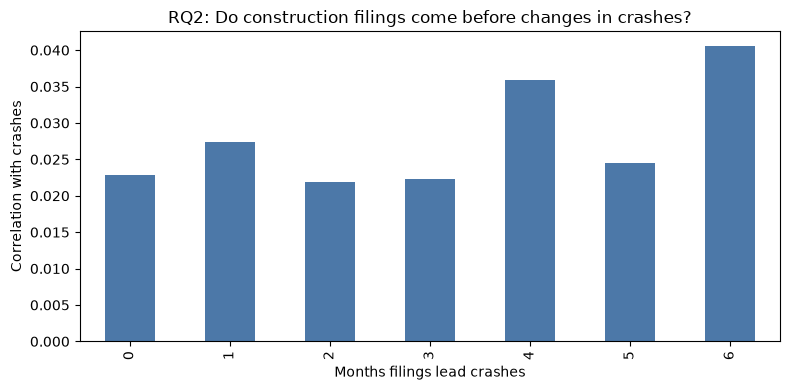

In [7]:
LAG_MONTHS = range(0, 7)
df = df.sort_values(["community_district", "year_month"])

# Correlate this month's crashes with new filings from 0 to 6 months earlier
lag_results = []
for lag in LAG_MONTHS:
    lagged_filings = df.groupby("community_district")["new_filings"].shift(lag)
    lag_results.append({"lag_months": lag, "corr": df["crashes"].corr(lagged_filings)})

lag_df = pd.DataFrame(lag_results)
print(lag_df)

ax = lag_df.plot.bar(x="lag_months", y="corr", legend=False, figsize=(8, 4), color="#4C78A8")
ax.set_xlabel("Months filings lead crashes")
ax.set_ylabel("Correlation with crashes")
ax.set_title("RQ2: Do construction filings come before changes in crashes?")
plt.tight_layout()
plt.show()

## RQ2: Do construction filings come before changes in crashes?

This chart tests whether new construction filings in a district predict crash counts 0 to 6 months later. Each bar shows the correlation between monthly crashes and filings at one lag.

All correlations are between 0.02 and 0.04. The strongest is at a 6-month lag (0.04), but this is too small to be meaningful. We found no evidence that construction filings come before changes in crash counts within this time window.

This null result has limits. The correlation pools all districts and months, so differences between districts may hide smaller patterns within each district. Filings measure permit activity, not actual construction, and the data covers only 2022 to 2026. A district-level analysis or a longer time series could give a clearer answer.

In [4]:
import pandas as pd
from pathlib import Path

# Look for Member 3's integrated output in the outputs folder
integration_dir = Path("../outputs/member3_integration")
candidates = sorted(integration_dir.glob("*.csv"))
print("Found:", [p.name for p in candidates])

# Load the first CSV found; change this if there are several
df = pd.read_csv(integration_dir / "cd_month.csv", low_memory=False)

print(df.shape)
print(df.columns.tolist())
df.head()

Found: ['borough_month.csv', 'cd_month.csv', 'cd_total.csv', 'crashes_with_district.csv', 'data_dictionary.csv']
(3186, 15)
['community_district', 'cd_label', 'borough', 'year_month', 'year', 'month', 'new_filings', 'new_units', 'is_large_pipeline_month', 'crashes', 'severe_inj', 'fatalities', 'ksi', 'history_known', 'repeat_location']


,community_district,cd_label,borough,year_month,year,month,new_filings,new_units,is_large_pipeline_month,crashes,severe_inj,fatalities,ksi,history_known,repeat_location
0,101,MN 01,MANHATTAN,2022-01,2022,1,0,0,False,1,1,0,1,1,0
1,101,MN 01,MANHATTAN,2022-02,2022,2,1,0,False,1,1,0,1,1,0
2,101,MN 01,MANHATTAN,2022-03,2022,3,0,0,False,0,0,0,0,0,0
3,101,MN 01,MANHATTAN,2022-04,2022,4,0,0,False,0,0,0,0,0,0
4,101,MN 01,MANHATTAN,2022-05,2022,5,0,0,False,1,1,0,1,1,0


In [3]:
   import pandas, ipykernel
   print("pandas", pandas.__version__, "| ipykernel OK")

pandas 3.1.0 | ipykernel OK
